<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS14/datasetPBL/TugasPraktikum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Modifikasi model CNN pada praktikum 2 sehingga didapatkan akurasi testing lebih dari 80%

In [1]:
import tensorflow as tf
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Load dan gabungkan kedua dataset asli
df_cafes = pd.read_csv('cafes.csv')
df_reviews = pd.read_csv('reviews.csv')
df = pd.merge(df_reviews, df_cafes, on='cafe_id', how='left', suffixes=('_review', '_cafe'))

# Ekstraksi fitur teks TF-IDF menjadi matriks (32, 32, 3) = 3.072 fitur
tfidf = TfidfVectorizer(max_features=32 * 32 * 3, ngram_range=(1, 2))
X_flat = tfidf.fit_transform(df['text'].astype(str)).toarray()

if X_flat.shape[1] < 32 * 32 * 3:
    X_flat = np.pad(X_flat, ((0, 0), (0, (32 * 32 * 3) - X_flat.shape[1])), mode='constant')

X_images = X_flat.reshape(-1, 32, 32, 3)

# Encode target 5 kelas (rating_review 1.0 s.d. 5.0)
le = LabelEncoder()
y_labels = le.fit_transform(df['rating_review']).reshape(-1, 1)

train_images, test_images, train_labels, test_labels = train_test_split(
    X_images, y_labels, test_size=0.2, random_state=42, stratify=y_labels
)

In [2]:
model = models.Sequential([
    # Blok Konvolusi 1
    layers.Conv2D(32, (3, 3), padding='same', activation='relu', input_shape=(32, 32, 3)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 2
    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Blok Konvolusi 3
    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2, 2)),

    # Classifier (Fully Connected)
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(5)
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 357,061 (1.36 MB)

 Trainable params: 356,613 (1.36 MB)

 Non-trainable params: 448 (1.75 KB)

Epoch 1/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 99ms/step - accuracy: 0.7567 - loss: 1.0356 - val_accuracy: 0.0583 - val_loss: 2.8010
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 11s 120ms/step - accuracy: 0.8246 - loss: 0.5924 - val_accuracy: 0.0583 - val_loss: 4.2536
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 93ms/step - accuracy: 0.8621 - loss: 0.4279 - val_accuracy: 0.0583 - val_loss: 3.6828
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 7s 119ms/step - accuracy: 0.9036 - loss: 0.3038 - val_accuracy: 0.0897 - val_loss: 4.0742
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 5s 90ms/step - accuracy: 0.9406 - loss: 0.2225 - val_accuracy: 0.2511 - val_loss: 1.4851
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 107ms/step - accuracy: 0.9636 - loss: 0.1486 - val_accuracy: 0.4709 - val_loss: 1.1951
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 9s 93ms/step - accuracy: 0.9748 - loss: 0.0988 - val_accuracy: 0.7354 - val_loss: 0.8535
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 6s 116ms/step - accuracy: 0.9725 - loss: 0.1048 - val_accuracy: 0.793

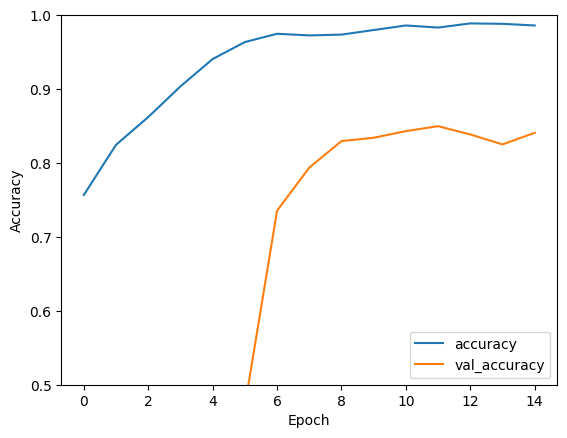

14/14 - 0s - 31ms/step - accuracy: 0.8408 - loss: 1.0611
Akurasi Testing: 84.08%


In [3]:
history = model.fit(
    train_images, train_labels,
    epochs=15,
    batch_size=32,
    validation_data=(test_images, test_labels)
)

# Plot grafik akurasi
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0.5, 1])
plt.legend(loc='lower right')
plt.show()

test_loss, test_acc = model.evaluate(test_images, test_labels, verbose=2)
print(f"Akurasi Testing: {test_acc * 100:.2f}%")

Model CNN Klasifikasi (Adaptasi Format MNIST 28 × 28 × 1 pada Dataset PBL)

In [4]:
# Ekstraksi 784 fitur (28 x 28 x 1) dari teks ulasan + nama kafe
tfidf_mnist = TfidfVectorizer(max_features=28 * 28, ngram_range=(1, 2))
X_784 = tfidf_mnist.fit_transform((df['name'] + " " + df['text'].astype(str))).toarray()

if X_784.shape[1] < 28 * 28:
    X_784 = np.pad(X_784, ((0, 0), (0, (28 * 28) - X_784.shape[1])), mode='constant')

# Reshape menjadi format citra grayscale 28x28x1 seperti MNIST
X_mnist_style = X_784.reshape(-1, 28, 28, 1)

# Target kelas: 5 kategori tempat usaha (categories)
le_cat = LabelEncoder()
y_cat = le_cat.fit_transform(df['categories'])
num_classes = len(le_cat.classes_)

x_train, x_test, y_train, y_test = train_test_split(
    X_mnist_style, y_cat, test_size=0.2, random_state=42, stratify=y_cat
)

print("Kelas kategori:", le_cat.classes_)
print("Shape x_train :", x_train.shape)
print("Shape x_test  :", x_test.shape)

Kelas kategori: ["['Grosir Kopi']" "['Kafe']" "['Kedai Kopi']" "['Toko Pakaian']"
 "['Toko']"]
Shape x_train : (1784, 28, 28, 1)
Shape x_test  : (446, 28, 28, 1)


In [5]:
cnn_mnist = models.Sequential([
    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax')
])

cnn_mnist.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_mnist = cnn_mnist.fit(
    x_train, y_train,
    epochs=15,
    batch_size=32,
    validation_data=(x_test, y_test)
)

loss_mnist, acc_mnist = cnn_mnist.evaluate(x_test, y_test, verbose=2)
print(f"Akurasi Model CNN (Format 28x28x1): {acc_mnist * 100:.2f}%")

Epoch 1/15


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 33ms/step - accuracy: 0.6900 - loss: 0.8075 - val_accuracy: 0.7108 - val_loss: 0.6534
Epoch 2/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.7225 - loss: 0.6320 - val_accuracy: 0.7377 - val_loss: 0.5744
Epoch 3/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - accuracy: 0.8016 - loss: 0.4967 - val_accuracy: 0.8251 - val_loss: 0.3971
Epoch 4/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.8851 - loss: 0.3277 - val_accuracy: 0.9350 - val_loss: 0.2471
Epoch 5/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 3s 46ms/step - accuracy: 0.9411 - loss: 0.2022 - val_accuracy: 0.9574 - val_loss: 0.1604
Epoch 6/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 40ms/step - accuracy: 0.9591 - loss: 0.1326 - val_accuracy: 0.9507 - val_loss: 0.1436
Epoch 7/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - accuracy: 0.9703 - loss: 0.0991 - val_accuracy: 0.9686 - val_loss: 0.1144
Epoch 8/15
56/56 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.9770 - loss: 0.0692 - val_accuracy: 0.9664 - val_loss: 0.